# NN_L4_fmnist_confusion

**Confusion matrix of the CNN on the 10,000 Fashion-MNIST test images (seed 20261108).**

Neural Networks and Deep Learning (NN), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L4/NN_L4_fmnist_confusion/NN_L4_fmnist_confusion.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Where the CNN errs: recall by class and the largest confusion.

lowest recall (%), Shirt = 75.1   [fmnist.worst_recall]
Shirt taken for T-shirt/top = 102   [fmnist.top_conf.n]


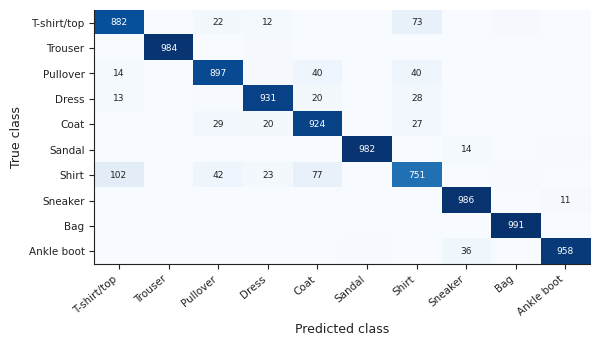

In [3]:
import json, urllib.request
_F = 'fmnist_confusion_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L4/NN_L4_fmnist_confusion/' + _F))
CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
cm = np.array(R['cm']); rec = cm.diagonal() / cm.sum(1)
show('fmnist.worst_recall', 'lowest recall (%), ' + CLASSES[int(rec.argmin())], round(100 * float(rec.min()), 1))
off = cm.copy(); np.fill_diagonal(off, 0); i, j = np.unravel_index(off.argmax(), off.shape)
show('fmnist.top_conf.n', f'{CLASSES[i]} taken for {CLASSES[j]}', int(off[i, j]))
fig, ax = plt.subplots(figsize=(6.4, 3.3)); cmn = cm / cm.sum(1, keepdims=True) * 100
ax.imshow(cmn, cmap='Blues', vmin=0, vmax=100, aspect='auto')
for i in range(10):
    for j in range(10):
        if cm[i, j] >= 10: ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=6.5, color='white' if cmn[i, j] > 50 else '#222222')
ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xticklabels(CLASSES, rotation=40, ha='right', fontsize=7.5); ax.set_yticklabels(CLASSES, fontsize=7.5)
ax.set_xlabel('Predicted class', fontsize=9); ax.set_ylabel('True class', fontsize=9)
fig.savefig('fmnist_confusion.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()